In [1]:
%matplotlib inline
import os
import pandas as pd
import numpy as np
import datetime
import math

# import sys
# !{sys.executable} -m pip install --user pyarrow 
import pyarrow
import pyarrow.parquet

from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import re
import copy
from pandas.tseries.holiday import USFederalHolidayCalendar as calendar

pd.set_option('display.max_columns', None)

In [2]:
## Setup 
import yaml
from yaml.loader import BaseLoader  # Load everything as String

yaml_def_file = 'xcache_def.yaml'
with open(yaml_def_file, 'r') as xfile:
    xcdef = yaml.load(xfile, Loader=BaseLoader)

def mode_assert(x, y):
    regions = ['socal', 'chic', 'bost']
    outmodes = ['daily', 'hourly']
    assert region in regions and isinstance(region, str), \
        f"region \'{region}\' is not in {regions}"
    assert outmode in outmodes and isinstance(outmode, str), \
        f"region \'outmode\' is not in outmodes"

In [3]:
## Cache: SoCal, Chicago, Boston
region = xcdef['region']  # ['socal', 'chic', 'bost']
from_yy, from_mm = xcdef[region]['from_yy'], xcdef[region]['from_mm']  # start year in yy, month in mm
to_yy, to_mm = xcdef[region]['to_yy'], xcdef[region]['to_mm']  # end year in yy, to month in mm

outmode = xcdef['outmode']  # daily or hourly

mode_assert(region, outmode)

In [4]:
outdir = xcdef['outdir']
try:
    os.mkdir(outdir)
except Exception as err:
    print(f"Unexpected {err}")
try:
    os.mkdir(f'{outdir}/df') # dataframe pickle outputs
except Exception as err:
    print(f"Unexpected {err}")

outprefix=f'{region}-{from_yy+from_mm}-{to_yy+to_mm}'  # f'{outprefix}-filename'
dfoutprefix=f'{region}-{from_yy+from_mm}-{to_yy+to_mm}-{outmode}'  # f'{outprefix}-filename' for df files

print(region)
print(outmode)
print(outprefix)
print(dfoutprefix)

Unexpected [Errno 17] File exists: './pickled_data'
Unexpected [Errno 17] File exists: './pickled_data/df'
socal
hourly
socal-2006-2403
socal-2006-2403-hourly


In [5]:
### Setup for plots
plotdir = xcdef['plotdir']
plotprefix=f'{region}-{from_yy+from_mm}-{to_yy+to_mm}-{outmode}'  # f’{plotprefix}-filename’
try:
    os.mkdir(plotdir)
except Exception as err:
    print(f"Unexpected {err}")
try:
    os.mkdir(f'{plotdir}/{region}')
except Exception as err:
    print(f"Unexpected {err}")
try:
    os.mkdir(f'{plotdir}/{region}/{outmode}')
except Exception as err:
    print(f"Unexpected {err}")
try:
    os.mkdir(f'{plotdir}/{region}/{outmode}/ts')
except Exception as err:
    print(f"Unexpected {err}")

print(plotprefix)

label_col = ['Count', 'TB', 'Count', 'TB', 'Count', 'TB']
if (outmode == 'daily'):
    title_col = ['daily access counts', 'daily access size', 'daily cache hit counts', 
                 'daily cache hit size', 'daily cache miss counts', 'daily cache miss size']
elif (outmode == 'hourly'):
    title_col = ['hourly access counts', 'hourly access size', 'hourly cache hit counts', 
                 'hourly cache hit size', 'hourly cache miss counts', 'hourly cache miss size']
else:
    print(f"Unexpected {outmode}")

socal-2006-2403-hourly


## Read in dataframe input

In [6]:
df = pd.read_pickle(f'{outdir}/df/{dfoutprefix}-ml')
print(len(df))
print(df.columns)

33611
Index(['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count',
       'miss_size'],
      dtype='object')


## Data conversion

In [7]:
## Convert sizes in TB
BtoTB = (1000 **4)
df.loc[:, ['access_size', 'hit_size', 'miss_size']] = df.loc[:, ['access_size', 'hit_size', 'miss_size']] / BtoTB

## Fill na with 0 and replace inf to 0
df.replace(np.inf, 0, inplace=True)
df = df.fillna(0)

## ML with Tensorflow

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense, Dropout

from keras.models import Sequential
#from keras.layers.recurrent import LSTM
from keras.layers import LSTM
from keras.layers.core import Dense, Activation, Dropout

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle

In [9]:
data_raw = df.values.astype("float32")

# ## MinMax scaler from sklearn to normalize data in the (0, 1) interval
# scaler = MinMaxScaler(feature_range = (0, 1))
## Standard scaler from sklearn to normalize data
scaler = StandardScaler()

dataset = scaler.fit_transform(data_raw)

In [10]:
print(dataset.shape)
print(dataset.max(), dataset.min())

(33611, 6)
38.03229 -0.8478303


In [11]:
# Using 80% of data for training, 20% for validation.
TRAIN_SIZE = 0.80

train_size = int(len(dataset) * TRAIN_SIZE)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size, :], dataset[train_size:len(dataset), :]

print("Number of entries (training set, test set): " + str((len(train), len(test))))

Number of entries (training set, test set): (26888, 6723)


In [12]:
# Create test and training sets for one-step-ahead regression
def create_dataset(dataset, window_size = 1):
    data_X, data_Y = [], []
    for i in range(len(dataset) - window_size - 1):
        a = dataset[i:(i + window_size),]
        data_X.append(a)
        data_Y.append(dataset[[i + window_size],])
    return(np.array(data_X), np.array(data_Y))
    
window_size = 1
train_X, train_Y = create_dataset(train, window_size)
test_X, test_Y = create_dataset(test, window_size)
print("Original training data shape:")
print(train_X.shape, train_Y.shape)
print(test_X.shape, test_Y.shape)

Original training data shape:
(26886, 1, 6) (26886, 1, 6)
(6721, 1, 6) (6721, 1, 6)


In [13]:
## reshape input to be [samples, time steps, features]
train_X = np.reshape(train_X, (train_X.shape[0], window_size, train_X.shape[2]))
test_X = np.reshape(test_X, (test_X.shape[0], window_size, test_X.shape[2]))
print(train_X.shape, test_X.shape)

(26886, 1, 6) (6721, 1, 6)


In [14]:
# define the Autoencoder model
model = Sequential()

model.add(LSTM(128, activation='relu', 
               input_shape=(train_X.shape[1], train_X.shape[2]), return_sequences=True,  dropout=0.1, recurrent_dropout=0.15))
# model.add(LSTM(32, activation='tanh', return_sequences=False))
# model.add(Dropout(0.2))
model.add(Dense(train_Y.shape[2]))

model.compile(loss = "mean_squared_error", optimizer = "adam")
model.summary()

history = model.fit(train_X, train_Y, epochs = 50, batch_size = 50, validation_data=(test_X, test_Y),verbose = 2)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 1, 128)            69120     
                                                                 
 dense (Dense)               (None, 1, 6)              774       
                                                                 
Total params: 69,894
Trainable params: 69,894
Non-trainable params: 0
_________________________________________________________________
Epoch 1/50


2024-07-03 12:23:25.783247: W tensorflow/tsl/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


538/538 - 1s - loss: 0.3573 - val_loss: 0.5537 - 1s/epoch - 3ms/step
Epoch 2/50
538/538 - 1s - loss: 0.2593 - val_loss: 0.5276 - 775ms/epoch - 1ms/step
Epoch 3/50
538/538 - 1s - loss: 0.2526 - val_loss: 0.5335 - 796ms/epoch - 1ms/step
Epoch 4/50
538/538 - 1s - loss: 0.2572 - val_loss: 0.5277 - 784ms/epoch - 1ms/step
Epoch 5/50
538/538 - 1s - loss: 0.2403 - val_loss: 0.5329 - 794ms/epoch - 1ms/step
Epoch 6/50
538/538 - 1s - loss: 0.2380 - val_loss: 0.5302 - 788ms/epoch - 1ms/step
Epoch 7/50
538/538 - 1s - loss: 0.2299 - val_loss: 0.5292 - 786ms/epoch - 1ms/step
Epoch 8/50
538/538 - 1s - loss: 0.2385 - val_loss: 0.5336 - 788ms/epoch - 1ms/step
Epoch 9/50
538/538 - 1s - loss: 0.2341 - val_loss: 0.5299 - 783ms/epoch - 1ms/step
Epoch 10/50
538/538 - 1s - loss: 0.2307 - val_loss: 0.5311 - 799ms/epoch - 1ms/step
Epoch 11/50
538/538 - 1s - loss: 0.2338 - val_loss: 0.5296 - 810ms/epoch - 2ms/step
Epoch 12/50
538/538 - 1s - loss: 0.2323 - val_loss: 0.5363 - 790ms/epoch - 1ms/step
Epoch 13/50
538

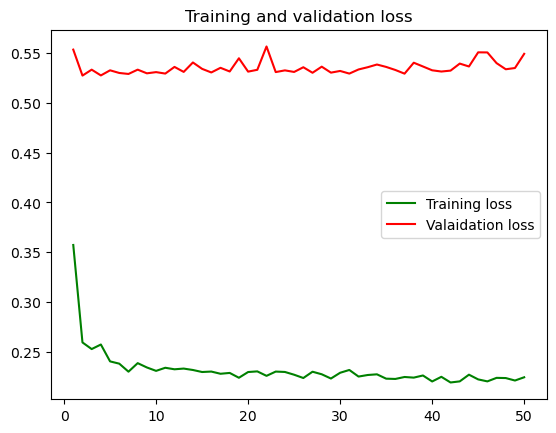

In [15]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(loss)+1)

plt.figure()
plt.plot(epochs, loss, 'g', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Valaidation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()

In [16]:
def predict_and_score(model, X, Y):
    # Make predictions on the original scale of the data.
    mpr = model.predict(X).reshape(Y.shape[0], Y.shape[2])
    # mpr = np.c_[ mpr, np.zeros(Y.shape[0]), np.zeros(Y.shape[0])]   
    pred = scaler.inverse_transform(mpr)
    return pred

train_predict = predict_and_score(model, train_X, train_Y)
test_predict = predict_and_score(model, test_X, test_Y)

211/211 [==============================] - 0s 286us/step


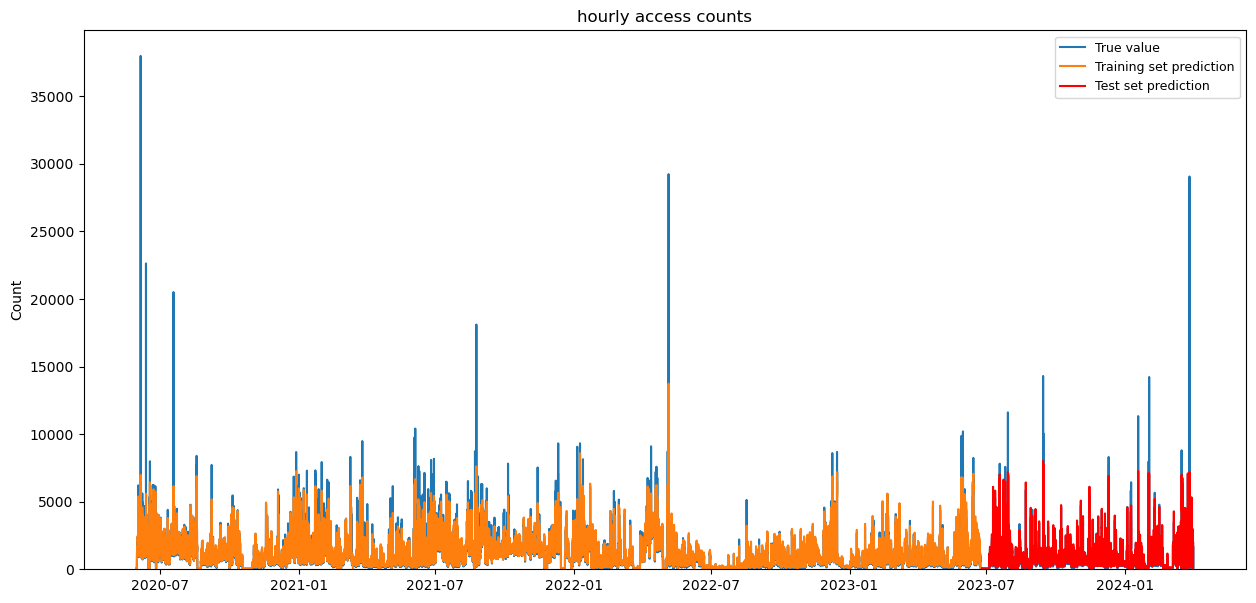

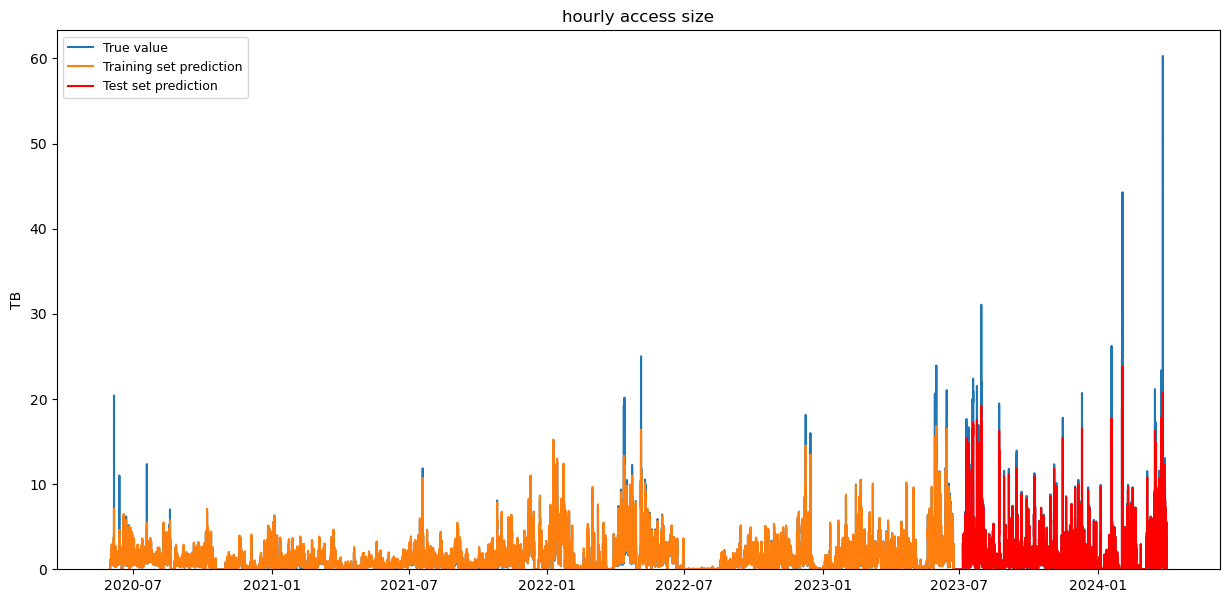

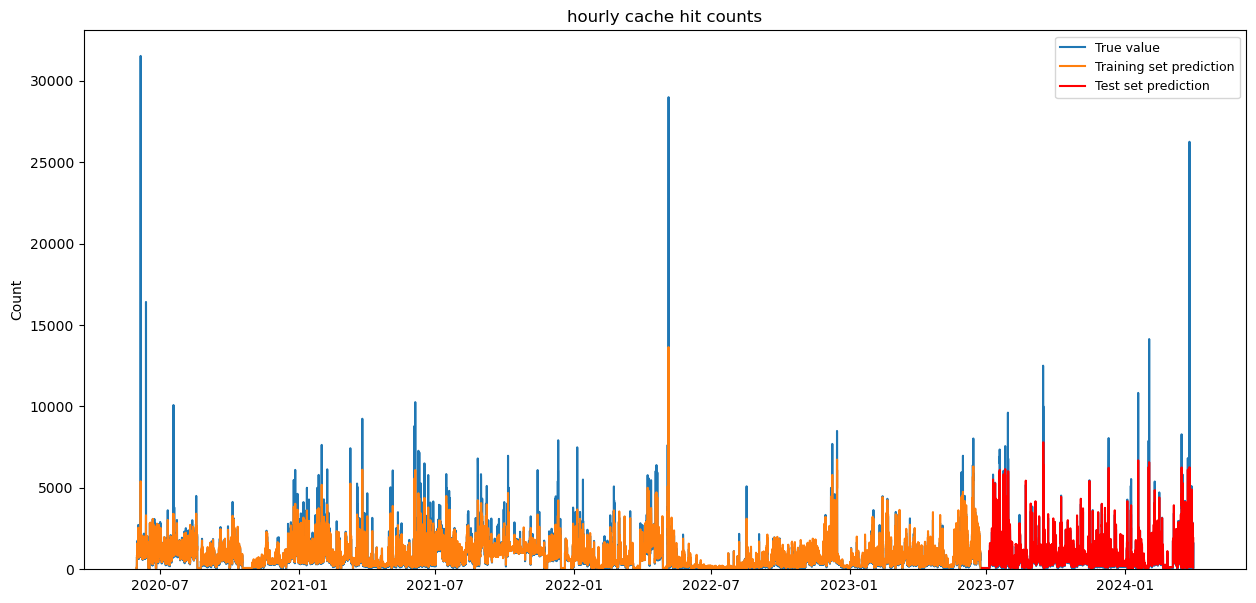

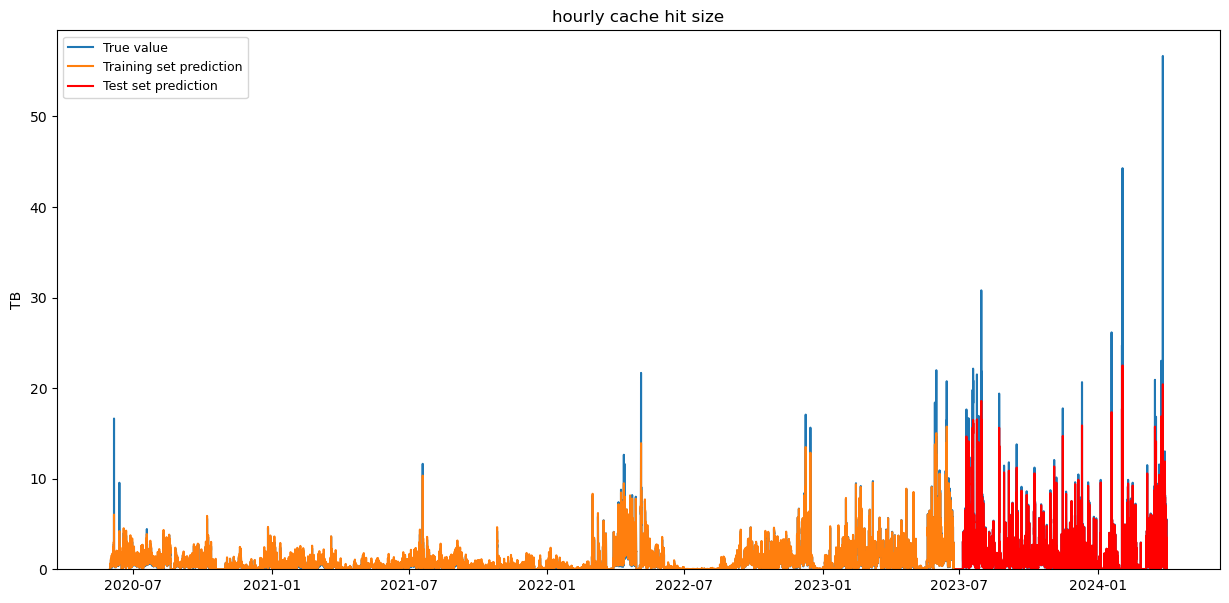

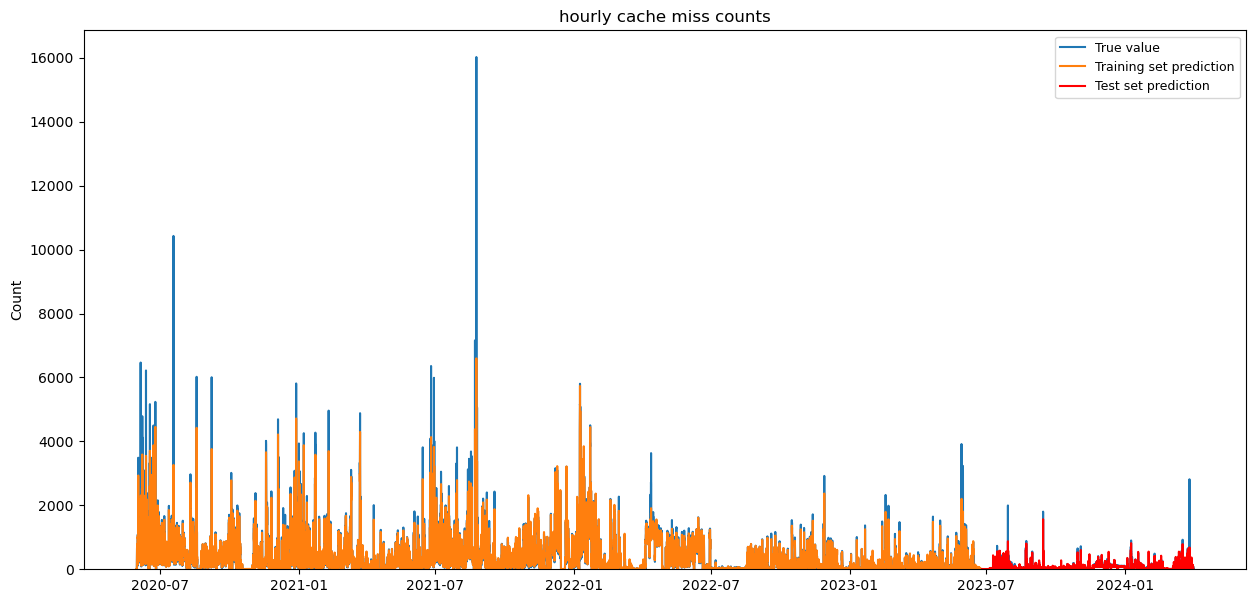

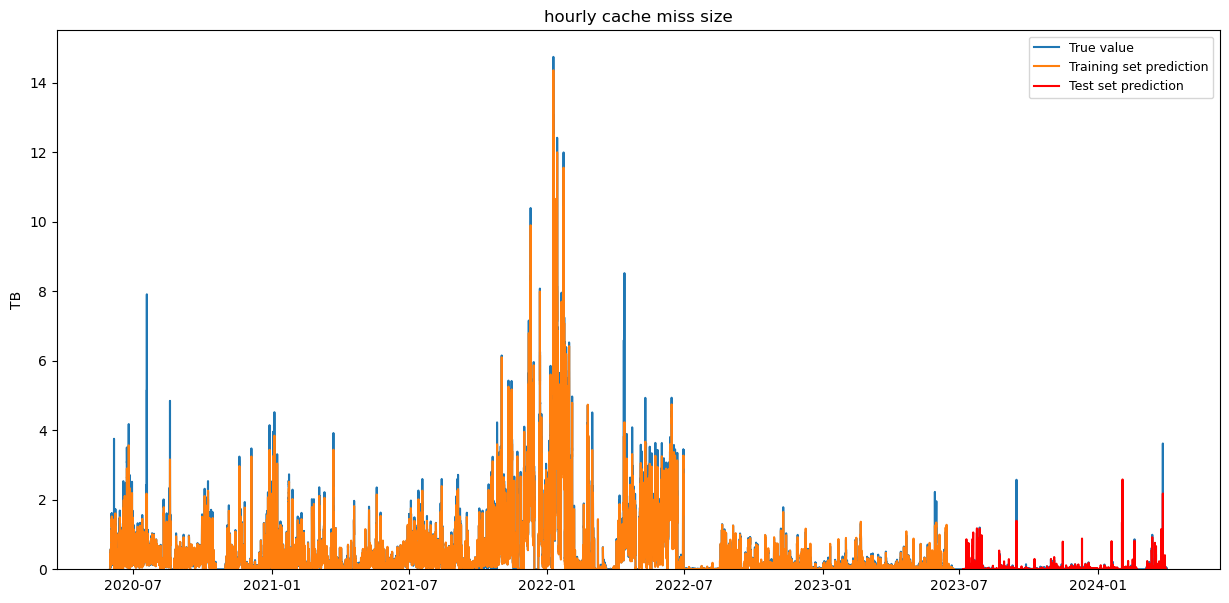

In [17]:
orgdata = {}
pred_train = {}
pred_test = {}

for idx in range(len(list(df))):
    name = list(df)[idx]

    # Start with training predictions.
    # window_size = 1
    train_predict_plot = np.empty_like(dataset[:, [idx]])
    train_predict_plot[:, :] = np.nan
    train_predict_plot[window_size -1:len(train_predict[:, [idx]]) + window_size - 1, :] = train_predict[:, [idx]]

    # Add test predictions.
    test_predict_plot = np.empty_like(dataset[:, [idx]])
    test_predict_plot[:, :] = np.nan
    test_predict_plot[len(train_predict[:, [idx]]) + (window_size * 2) + 1 - 1:len(dataset) - 1 - 1, :] = test_predict[:, [idx]]

    # Create the plot.
    coldata = pd.DataFrame(data = {'True': scaler.inverse_transform(dataset)[:, [idx]].reshape(-1), 
                                   'Train': train_predict_plot.reshape(-1), 
                                   'Test':test_predict_plot.reshape(-1)}, 
                            index = df.index)
    
    plt.figure(figsize = (15, 7))
    
    plt.plot(coldata['True'], label = "True value")
    plt.plot(coldata['Train'], label = "Training set prediction")
    plt.plot(coldata['Test'], label = "Test set prediction", color = 'red')

    orgdata[name] =scaler.inverse_transform(dataset)[:, [idx]]
    pred_train[name] = train_predict_plot
    pred_test[name] = test_predict_plot
    
    plt.ylim(bottom = 0)
    plt.ylabel(label_col[idx])
    plt.title(title_col[idx])
    plt.legend(fontsize='9')
    # plt.savefig(f'{plotdir}/{region}/{outmode}/ts/{plotprefix}-lstm_keras-{name}.png', dpi=600, bbox_inches="tight")
    plt.show()

In [18]:
stuff_r = []
train_r = []
test_r = []
for idx in range(len(list(df))):
    result = pd.DataFrame(index = df.index)
    result['org'] = orgdata[list(df)[idx]]
    result['train'] = pred_train[list(df)[idx]]
    result['test'] = pred_test[list(df)[idx]]
    temp_train = result.loc[:, ['org', 'train']].dropna()
    temp_test = result.loc[:, ['org', 'test']].dropna()
    train_rmse = math.sqrt(mean_squared_error(temp_train['org'], temp_train['train']))
    test_rmse = math.sqrt(mean_squared_error(temp_test['org'], temp_test['test']))
    stuff_r.append(list(df)[idx])
    train_r.append(train_rmse)
    test_r.append(test_rmse)
    
RMSE_df = pd.DataFrame(data = {'Train_RMSE': train_r, 'Test_RMSE': test_r}, index = list(df)[:])
RMSE_df

,Train_RMSE,Test_RMSE
access_count,346.065068,376.784939
access_size,0.216258,0.682953
hit_count,288.475844,333.948911
hit_size,0.181483,0.677250
miss_count,117.838848,64.220753
miss_size,0.097690,0.076273


In [19]:
import statistics
print("std of access_count:  "+str(df['access_count'].std(numeric_only=True)))
print("std of access_size:   "+str(df['access_size'].std(numeric_only=True)))
print("std of hit_count:  "+str(df['hit_count'].std(numeric_only=True)))
print("std of hit_size:   "+str(df['hit_size'].std(numeric_only=True)))
print("std of miss_count: "+str(df['miss_count'].std(numeric_only=True)))
print("std of miss_size:  "+str(df['miss_size'].std(numeric_only=True)))

# print(statistics.stdev(pred_test))

std of access_count:  1085.7146247579929
std of access_size:   1.783548429666004
std of hit_count:  811.6740184518433
std of hit_size:   1.5420402147241201
std of miss_count: 485.1490410848458
std of miss_size:  0.84631928173911
